<a href="https://colab.research.google.com/github/vincentmartin/tp-initiation-llm-student-version/blob/main/TP_initiation_llm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP d'initiation aux LLM

Dans ce TP, vous allez apprendre les bases de l'IA générative en manipulant et en contrôlant un LLM **open-weight** exécuté localement sur le GPU de Colab : aucun compte payant ni clé d'API n'est nécessaire.

En sortie de ce TP, vous serez capable de :
- Expliquer ce qu'est un token, un tokenizer, un *chat template* et une fenêtre de contexte
- Observer ce que calcule réellement un LLM : une distribution de probabilité sur le token suivant
- Distinguer un modèle *base* d'un modèle *instruct*, et utiliser un modèle de raisonnement (*thinking*)
- Appliquer les techniques de prompt engineering : system prompt, zero-shot, one-shot, few-shot
- Contrôler la génération (température, top-k, top-p, échantillonnage)
- Évaluer des sorties de LLM (ROUGE, LLM-as-a-judge)
- Obtenir des sorties structurées (JSON validé par Pydantic)
- Utiliser un LLM pour structurer des données et alimenter une base, ou pour classer des textes à partir de ses probabilités

**Modèle utilisé** : [Qwen3-1.7B](https://huggingface.co/Qwen/Qwen3-1.7B) (Alibaba, licence Apache 2.0). Petit, multilingue, avec un mode raisonnement activable : il tient sans problème sur le GPU T4 gratuit de Colab.

### Instructions pour l'exécution sur Google Colab

Aller dans `Exécution -> Modifier le type d'exécution` puis sélectionner `T4 GPU`.

![Colab GPU](https://raw.githubusercontent.com/vincentmartin/tp-initiation-llm-student-version/main/resources/colab_gpu.png "T4-GPU")

**Pas de GPU disponible sur Colab ?** (quota atteint, heure de pointe) : utilisez [Kaggle Notebooks](https://www.kaggle.com/code), gratuit avec environ 30 h de GPU par semaine (`Settings -> Accelerator -> GPU T4 x2`, et activer `Internet` après vérification du compte par téléphone). Importez ce notebook via `File -> Import Notebook`.

**Assistants IA** : vous pouvez utiliser l'assistant intégré à Colab, mais vous devez être capables d'expliquer **chaque ligne** du code que vous rendez. Les questions d'analyse comptent autant que le code.

**Indices** : la plupart des exercices sont suivis d'indices repliables (💡, cliquez pour les ouvrir). Cherchez d'abord par vous-mêmes, puis ouvrez-les **un par un** : ils vont de la simple piste au squelette de code.

## 0. Installation et configuration

Colab fournit déjà `torch` : **ne le réinstallez pas**, cela casserait la compatibilité avec CUDA. Nous mettons simplement à jour les bibliothèques Hugging Face :
- **transformers** : chargement et utilisation des modèles de type Transformer
- **accelerate** : placement automatique du modèle sur le GPU
- **datasets** : téléchargement de jeux de données depuis le Hub Hugging Face
- **evaluate** / **rouge_score** : métriques d'évaluation

In [1]:
%pip install -q -U transformers accelerate datasets evaluate rouge_score

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


**Remarque** : si l'import ci-dessous échoue juste après l'installation, redémarrez la session (`Exécution -> Redémarrer la session`) puis relancez les cellules à partir d'ici.

In [3]:
import gc
import json
import re
import time

import matplotlib.pyplot as plt
import pandas as pd
import torch
import transformers
from datasets import load_dataset
from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed

print(f"torch {torch.__version__} | transformers {transformers.__version__}")

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cuda":
    print("GPU :", torch.cuda.get_device_name(0))
    # Le T4 (architecture Turing, compute capability 7.5) ne gère pas nativement le bfloat16 :
    # on utilise float16 sur ce type de GPU, bfloat16 sur les GPU récents (Ampere et +).
    DTYPE = torch.bfloat16 if torch.cuda.get_device_capability()[0] >= 8 else torch.float16
else:
    print("ATTENTION : pas de GPU, l'exécution sera très lente. Vérifiez le type d'exécution.")
    DTYPE = torch.float32

set_seed(42)

torch 2.14.1+cu130 | transformers 5.23.0
GPU : Tesla T4


## 1. Tokenisation

Un LLM ne manipule pas des caractères ni des mots, mais des **tokens** : des morceaux de mots issus d'un vocabulaire fixe (environ 150 000 tokens pour Qwen3). Le **tokenizer** convertit le texte en une suite d'identifiants entiers (*ids*) et inversement.

Chargeons le tokenizer de notre modèle.

In [4]:
MODEL_NAME = "Qwen/Qwen3-1.7B"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
print(f"Taille du vocabulaire : {len(tokenizer)}")

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

Taille du vocabulaire : 151669


**Exercice 1** : en vous aidant de la [documentation des tokenizers](https://huggingface.co/docs/transformers/main_classes/tokenizer) :
- encoder la phrase en une liste d'ids et l'afficher ;
- afficher les tokens correspondant à ces ids (méthode `convert_ids_to_tokens`) ;
- décoder la liste d'ids pour retrouver la phrase.

<details>
<summary>💡 Indice 1 : encoder</summary>

Le tokenizer s'appelle comme une fonction : `tokenizer(sentence)` renvoie un dictionnaire. Affichez-le : les ids sont sous la clé `"input_ids"`.

</details>

<details>
<summary>💡 Indice 2 : afficher les tokens et décoder</summary>

- `tokenizer.convert_ids_to_tokens(liste_d_ids)` renvoie les tokens sous forme de chaînes ;
- `tokenizer.decode(liste_d_ids)` fait l'opération inverse de l'encodage.

</details>

In [5]:


sentence = "Que peux-tu me dire sur les LLMs ?"

encoded = tokenizer(sentence)
print(encoded)
ids = encoded["input_ids"]
print("ids :", ids)

tokens = tokenizer.convert_ids_to_tokens(ids)
print("tokens :", tokens)

print("décodé :", tokenizer.decode(ids))



{'input_ids': [25776, 93197, 2385, 84, 752, 13207, 1729, 3541, 444, 10994, 82, 937], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}
ids : [25776, 93197, 2385, 84, 752, 13207, 1729, 3541, 444, 10994, 82, 937]
tokens : ['Que', 'Ġpeux', '-t', 'u', 'Ġme', 'Ġdire', 'Ġsur', 'Ġles', 'ĠL', 'LM', 's', 'Ġ?']
décodé : Que peux-tu me dire sur les LLMs ?


Le caractère `Ġ` représente un espace : il fait partie du token qui le suit.

**Exercice 2** : comparons le nombre de tokens nécessaires pour une même phrase en français et en anglais, avec le tokenizer de Qwen3 et celui de `flan-t5`, le modèle utilisé dans les versions précédentes de ce TP (2022). Écrire une fonction `count_tokens(tok, text)` puis compléter le tableau.

<details>
<summary>💡 Indice 1 : compter les tokens</summary>

Le nombre de tokens est simplement la longueur de la liste d'ids obtenue à l'exercice 1. La fonction tient en une ligne et doit utiliser le paramètre `tok` (et non la variable globale `tokenizer`) : elle est appelée avec les deux tokenizers.

</details>

<details>
<summary>💡 Indice 2 : une comparaison équitable</summary>

Certains tokenizers ajoutent des tokens spéciaux qui ne correspondent à aucun mot du texte (par exemple `</s>` en fin de séquence pour `flan-t5`). Passez `add_special_tokens=False` au tokenizer pour ne compter que les tokens du texte.

</details>

In [6]:


old_tokenizer = AutoTokenizer.from_pretrained("google/flan-t5-base")

sentences = {
    "fr": "L'intelligence artificielle générative transforme profondément le développement logiciel.",
    "en": "Generative artificial intelligence is profoundly transforming software development.",
}


def count_tokens(tok, text):
    # VOTRE CODE ICI
    encoded = tok(text)
    ids = encoded["input_ids"]
    tokens = tokenizer.convert_ids_to_tokens(ids)
    print("tokens :", tokens)
    return len(ids)


pd.DataFrame({
    name: {lang: count_tokens(tok, text) for lang, text in sentences.items()}
    for name, tok in {"Qwen3": tokenizer, "flan-t5": old_tokenizer}.items()
})



config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.20k [00:00<?, ?B/s]

tokens : ['L', "'int", 'elligence', 'Ġart', 'ific', 'i', 'elle', 'ĠgÃ©nÃ©r', 'ative', 'Ġtransform', 'e', 'Ġprof', 'ond', 'Ã©ment', 'Ġle', 'ĠdÃ©veloppement', 'Ġlog', 'iciel', '.']
tokens : ['Gener', 'ative', 'Ġartificial', 'Ġintelligence', 'Ġis', 'Ġprofoundly', 'Ġtransforming', 'Ġsoftware', 'Ġdevelopment', '.']
tokens : ['el', '@', 'NON', 'ug', 'ixed', '8', 'Re', 'available', 'che', 'Ġproperty', '0', 'Er', 'Then', '{', 'ĠTop', 'Ġindustrial', '&', '"']
tokens : ['Ġ$("#', 'R', 'che', '.style', 'Fe', '4', 'æĹ¶', '¼', '$', 'ĠPitt', 'vel', 'name', '&', '"']


,Qwen3,flan-t5
fr,19,18
en,10,14


**Question** : pourquoi le français demande-t-il plus de tokens que l'anglais ? Quelles conséquences pratiques cela a-t-il (coût d'une API facturée au token, vitesse, fenêtre de contexte) ? Affichez aussi les tokens de la phrase française avec `flan-t5` : que remarquez-vous ?

<details>
<summary>💡 Indice</summary>

Pour voir les tokens de `flan-t5` : `old_tokenizer.convert_ids_to_tokens(old_tokenizer(sentences["fr"])["input_ids"])`. Regardez ce que deviennent les lettres accentuées.

</details>

✍️ **Votre réponse :** Car le francais est bcp plus verbeux et que la cantité d'information pour les entrainement est principalement réalisé en anglais. Cela a pour conséquence une API plus cher , vitesse plus lente et des fenetre de contexte plus petite. Flan-t5 consome moins car il ne fait pas la meme tokenisation , il creer moins de token pour le meme texte



### Le chat template

Les modèles conversationnels sont entraînés sur des conversations mises en forme avec des **tokens spéciaux** qui délimitent les rôles (`system`, `user`, `assistant`). Chaque famille de modèles a son propre format : le **chat template**, fourni avec le tokenizer. On ne l'écrit jamais à la main, on utilise `apply_chat_template`.

In [7]:
messages = [
    {"role": "system", "content": "Tu es un assistant concis qui répond en français."},
    {"role": "user", "content": "Quelle est la capitale de la France ?"},
]

prompt_text = tokenizer.apply_chat_template(
    messages,
    tokenize=False,              # renvoie le texte plutôt que les ids
    add_generation_prompt=True,  # ajoute le début du tour de l'assistant
    enable_thinking=False,       # désactive le mode raisonnement (voir partie 4)
)
print(prompt_text)

<|im_start|>system
Tu es un assistant concis qui répond en français.<|im_end|>
<|im_start|>user
Quelle est la capitale de la France ?<|im_end|>
<|im_start|>assistant
<think>

</think>




**Question** : à quoi servent les tokens `<|im_start|>` et `<|im_end|>` ? Pourquoi le template se termine-t-il par `<|im_start|>assistant` ?

✍️ **Votre réponse :** il s'agit de balise qui délimite le texte des message du system et user.fini <|im_start|>assistant car Il appelle le llm a raisonner



### La fenêtre de contexte

Un modèle ne peut traiter qu'un nombre limité de tokens à la fois : c'est sa **fenêtre de contexte**.

In [8]:
print(f"flan-t5 : {old_tokenizer.model_max_length} tokens")
print(f"Qwen3   : {tokenizer.model_max_length} tokens")

del old_tokenizer

flan-t5 : 512 tokens
Qwen3   : 131072 tokens


Gardez ces chiffres en tête : nous verrons dans la partie 4 que la limite de 512 tokens de `flan-t5` faussait une partie des conclusions des anciennes versions de ce TP.

## 2. Sous le capot : prédire le token suivant

Chargeons le modèle sur le GPU (environ 3,5 Go en float16).

In [9]:
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=DTYPE, device_map="auto")
print(f"Mémoire occupée par le modèle : {model.get_memory_footprint() / 1e9:.1f} Go")

model.safetensors.index.json:   0%|          | 0.00/25.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Mémoire occupée par le modèle : 3.4 Go


Un LLM *causal* fait **une seule chose** : à partir d'une suite de tokens, il calcule un score (*logit*) pour chacun des ~150 000 tokens du vocabulaire. Un `softmax` transforme ces scores en probabilités pour le **token suivant**.

**Exercice 3** : compléter la fonction `next_token_distribution` qui renvoie le vecteur de probabilités du token suivant. Indications :
- `model(input_ids=...)` renvoie un objet dont l'attribut `logits` a la forme `(batch, longueur_séquence, taille_vocabulaire)` ;
- seuls les logits de la **dernière position** nous intéressent ;
- la température divise les logits **avant** le softmax.

<details>
<summary>💡 Indice 1 : les étapes</summary>

1. Encoder `text` en un **tenseur PyTorch** (et non une liste) : paramètre `return_tensors="pt"`. On obtient des ids de forme `(1, longueur_séquence)` : un batch d'une seule phrase.
2. Déplacer ce tenseur sur le même device que le modèle (le GPU) : `.to(model.device)`.
3. Appeler le modèle et récupérer `.logits`.
4. Garder les logits de la dernière position, diviser par la température, appliquer `torch.softmax`.

</details>

<details>
<summary>💡 Indice 2 : pourquoi la dernière position ?</summary>

Le modèle calcule une prédiction **pour chaque position** : à la position `t`, il prédit le token `t+1` en ne voyant que les tokens `0..t`. Avec `"La capitale de la France est"` :

| position | le modèle a vu | il prédit le token après... |
|---|---|---|
| 0 | `La` | « La » (déjà connu) |
| 1 | `La capitale` | « capitale » (déjà connu) |
| ... | ... | ... |
| dernière | toute la phrase | « est » : **c'est ce qu'on cherche** |

Les autres positions servent pendant l'entraînement (on calcule l'erreur sur toutes les positions en parallèle), pas pour générer.

Un **logit** est un score brut (positif ou négatif, non borné) attribué à chaque token du vocabulaire. Le softmax $p_i = e^{z_i} / \sum_j e^{z_j}$ le transforme en probabilité.

</details>

<details>
<summary>💡 Indice 3 : indexation et détails pratiques</summary>

- `logits[0, -1]` : premier (et seul) élément du batch, dernière position. On obtient un vecteur de taille `taille_vocabulaire`.
- `torch.softmax(x, dim=-1)` normalise selon la dernière dimension.
- Entourez l'appel au modèle de `with torch.no_grad():` : on ne fait pas d'entraînement, inutile de stocker de quoi calculer les gradients (gain de mémoire et de temps).
- Les logits sont en float16 : `.float()` les convertit en float32 pour un softmax plus précis.
- Vérification : `next_token_distribution(text).sum()` doit valoir environ 1.

</details>

tensor([ 9.8203, 12.1328,  4.9570,  ..., -0.4873, -0.4873, -0.4873],
       device='cuda:0', dtype=torch.float16)


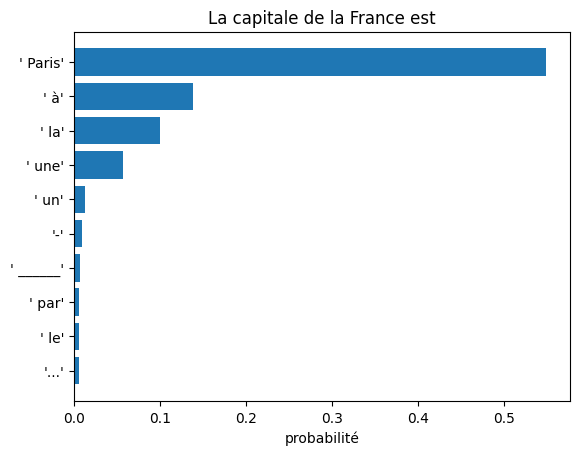

In [13]:
import torch

def next_token_distribution(text, temperature=1.0):
    """Renvoie le vecteur des probabilités du token suivant `text`."""
    # 1. Tokeniser le texte et l'envoyer sur le model
    inputs = tokenizer(text, return_tensors="pt").to(model.device)

    # 2. Passe avant sans calcul de gradient pour gagner en efficacité
    with torch.no_grad():
        outputs = model(input_ids=inputs["input_ids"])

    last_logits = outputs.logits[0, -1, :]

    # 4. Température : on divise les logits, puis softmax
    probs = torch.softmax(last_logits.float() / temperature, dim=-1)

    return probs


def plot_top_tokens(probs, k=10, title=""):
    """Affiche les k tokens les plus probables sous forme de diagramme en barres."""
    top = torch.topk(probs, k)
    labels = [repr(tokenizer.decode(i)) for i in top.indices]
    plt.barh(labels[::-1], top.values.cpu().numpy()[::-1])
    plt.xlabel("probabilité")
    plt.title(title)
    plt.show()


text = "La capitale de la France est"
plot_top_tokens(next_token_distribution(text), title=text)

**Exercice 4** : générer du texte, c'est appeler le modèle en boucle. Écrire la fonction `greedy_decode` qui, à chaque étape, choisit le token le plus probable (*greedy decoding*), l'ajoute à la séquence et recommence, jusqu'à `max_new_tokens` ou jusqu'au token de fin. Comparer avec le résultat de `model.generate(..., do_sample=False)`.

<details>
<summary>💡 Indice 1 : l'algorithme</summary>

```
encoder le texte -> input_ids, de forme (1, L)
mémoriser la longueur du prompt
répéter max_new_tokens fois :
    calculer les logits de la dernière position (comme à l'exercice 3)
    next_id <- indice du logit maximal
    ajouter next_id à la fin de input_ids
    si next_id est un token de fin : sortir de la boucle
décoder uniquement les tokens ajoutés
```
Le softmax est inutile ici : il ne change pas l'ordre des scores, donc le token de plus grand logit est aussi le plus probable.

</details>

<details>
<summary>💡 Indice 2 : les fonctions PyTorch utiles</summary>

- `logits.argmax()` : indice du maximum (tenseur à 0 dimension).
- `torch.cat([a, b], dim=1)` : concatène deux tenseurs selon la dimension des positions. `b` doit avoir la même forme que `a` sauf sur cette dimension, soit `(1, 1)` : `next_id.view(1, 1)`.
- `next_id.item()` convertit le tenseur en entier Python, pour tester `in EOS_IDS`.
- `input_ids[0, prompt_length:]` : les tokens générés seulement ; `tokenizer.decode(..., skip_special_tokens=True)` retire `<|im_end|>`.

</details>

In [19]:
EOS_IDS = model.generation_config.eos_token_id  # liste des ids qui terminent la génération


def greedy_decode(text, max_new_tokens=30):
    # VOTRE CODE ICI
    i=0
    text_ajouter=text
    while i!= max_new_tokens:
      probs = next_token_distribution(text_ajouter)
      top = torch.topk(probs, 1)
      next_id = top.indices[0].item()          # l'id du token gagnant (un entier)
      if next_id in EOS_IDS: # si on est arriver a la fin avant 30
            break
      text_ajouter += tokenizer.decode(next_id) # on le convertit en texte
      i=i+1
    return text_ajouter[len(text):]

start = time.perf_counter()
print("Notre boucle    :", repr(greedy_decode(prompt_text)), f"({time.perf_counter() - start:.1f} s)")

inputs = tokenizer(prompt_text, return_tensors="pt").to(model.device)
start = time.perf_counter()
output_ids = model.generate(**inputs, max_new_tokens=30, do_sample=False)
reference = tokenizer.decode(output_ids[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True)
print("model.generate  :", repr(reference), f"({time.perf_counter() - start:.1f} s)")

tensor([ 6.4922, 11.5078,  9.8906,  ...,  0.1064,  0.1064,  0.1064],
       device='cuda:0', dtype=torch.float16)
tensor([ 4.1875,  5.9102, -1.2812,  ..., -1.6836, -1.6836, -1.6836],
       device='cuda:0', dtype=torch.float16)
tensor([ 5.8438,  6.2344,  4.3867,  ..., -1.3389, -1.3389, -1.3389],
       device='cuda:0', dtype=torch.float16)
tensor([ 2.4434,  7.2227, -1.7617,  ..., -2.1211, -2.1211, -2.1211],
       device='cuda:0', dtype=torch.float16)
tensor([ 3.0488,  3.2598,  2.1543,  ..., -1.8047, -1.8047, -1.8047],
       device='cuda:0', dtype=torch.float16)
tensor([ 1.0225,  2.1289, -1.8281,  ..., -1.9229, -1.9229, -1.9229],
       device='cuda:0', dtype=torch.float16)
tensor([ 1.4102,  4.6484, -2.1855,  ..., -0.6729, -0.6729, -0.6729],
       device='cuda:0', dtype=torch.float16)
tensor([ 1.8545,  4.3086, -2.0859,  ..., -2.7305, -2.7305, -2.7305],
       device='cuda:0', dtype=torch.float16)
tensor([ 9.5859, -0.6362,  1.0303,  ..., -1.0859, -1.0859, -1.0859],
       device='cuda

**Question** : les deux sorties sont (normalement) identiques, mais `model.generate` est plus rapide. Notre boucle recalcule tout depuis le début à chaque token : quelle optimisation `generate` met-elle en place ? (indice : *KV cache*)

✍️ **Votre réponse :** generate optimise en gardant les calcul effectué au token précédent ce qui permet d'économiser et évite par exemple au token 30 de rééfectuer le calcul de 29 token précédent



**Exercice 5** : visualiser la distribution du token suivant pour des températures de 0.2, 1.0 et 2.0. Comment la température modifie-t-elle la distribution ? Quelle valeur choisir pour une tâche factuelle ? Pour de l'écriture créative ?

<details>
<summary>💡 Indice</summary>

Une simple boucle sur les températures suffit : réutilisez `next_token_distribution(text, temperature)` et `plot_top_tokens(...)`, en indiquant la température dans le titre. Pour l'analyse, comparez la probabilité du token le plus probable d'un graphique à l'autre.

</details>

In [ ]:
text = "Il était une fois un"

# VOTRE CODE ICI

✍️ **Votre réponse :**



## 3. Modèle *base* vs modèle *instruct*

Un LLM est construit en deux grandes étapes :
1. le **pré-entraînement** sur des milliers de milliards de tokens de texte brut : on obtient un modèle **base** qui sait compléter du texte ;
2. le **post-entraînement** (*instruction tuning*, puis apprentissage par renforcement) sur des conversations : on obtient un modèle **instruct** (ou *chat*) qui suit des consignes.

Comparons les deux versions de Qwen3-1.7B sur la même question.

In [ ]:
base_model = AutoModelForCausalLM.from_pretrained(f"{MODEL_NAME}-Base", dtype=DTYPE, device_map="auto")

question = "Quelle est la capitale de la France ?"

inputs = tokenizer(question, return_tensors="pt").to(base_model.device)
output_ids = base_model.generate(**inputs, max_new_tokens=60, do_sample=False)
print("BASE, texte brut :\n", tokenizer.decode(output_ids[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True))

chat_text = tokenizer.apply_chat_template(
    [{"role": "user", "content": question}], tokenize=False, add_generation_prompt=True, enable_thinking=False
)
inputs = tokenizer(chat_text, return_tensors="pt").to(model.device)
output_ids = model.generate(**inputs, max_new_tokens=60, do_sample=False)
print("\nINSTRUCT, chat template :\n", tokenizer.decode(output_ids[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True))

# Libérons la mémoire GPU : nous n'utiliserons plus le modèle base.
del base_model
gc.collect()
torch.cuda.empty_cache()

**Question** : décrivez le comportement du modèle base. Pourquoi « continue »-t-il le texte au lieu de répondre ?

✍️ **Votre réponse :**



## 4. Prompt engineering

### Une fonction de génération réutilisable

Pour ne pas répéter le même code à chaque cellule, écrivons une fonction de génération.

**Exercice 6** : compléter la fonction `generate` qui :
- applique le chat template à la liste de `messages` (avec `add_generation_prompt=True`, `enable_thinking=enable_thinking`, `return_tensors="pt"` et `return_dict=True`) et place le résultat sur le device du modèle ;
- appelle `model.generate` en lui transmettant `max_new_tokens` et les paramètres supplémentaires `**gen_kwargs` ;
- renvoie uniquement le texte **généré** (sans le prompt), sans tokens spéciaux et sans espaces superflus.

<details>
<summary>💡 Indice 1 : un exemple déjà présent</summary>

La cellule de l'exercice 4 qui appelle `model.generate` fait presque tout ce qui est demandé : relisez comment elle appelle `generate` et comment elle ne garde que les tokens générés.

</details>

<details>
<summary>💡 Indice 2 : ce que renvoient les fonctions</summary>

- Avec `return_dict=True` et `return_tensors="pt"`, `apply_chat_template` renvoie un dictionnaire (`input_ids`, `attention_mask`) de tenseurs. On le déplace sur le GPU avec `.to(model.device)` et on le passe tel quel à `model.generate(**inputs, ...)`.
- `model.generate` renvoie **le prompt suivi de la réponse** : un tenseur de forme `(1, longueur_prompt + longueur_générée)`. La longueur du prompt est `inputs["input_ids"].shape[1]`.
- `**gen_kwargs` se transmet tel quel : `model.generate(..., **gen_kwargs)`.
- `.strip()` retire les espaces et sauts de ligne au début et à la fin.

</details>

In [ ]:
def generate(messages, max_new_tokens=256, enable_thinking=False, **gen_kwargs):
    """Génère la réponse de l'assistant à une liste de messages au format chat."""
    # VOTRE CODE ICI
    raise NotImplementedError("À compléter")


# Vérification
answer = generate([{"role": "user", "content": "Quelle est la capitale de l'Italie ? Réponds en un mot."}], do_sample=False)
print(answer)
assert answer, "La réponse est vide."
assert "Réponds en un mot" not in answer, "La réponse contient le prompt : ne décodez que les tokens générés."
assert "<|im_end|>" not in answer, "La réponse contient des tokens spéciaux."

### Résumé de dialogues

Nous allons utiliser le LLM pour résumer des dialogues du dataset [DialogSum](https://huggingface.co/datasets/knkarthick/dialogsum), qui fournit pour chaque dialogue un résumé écrit par un humain.

In [ ]:
dataset = load_dataset("knkarthick/dialogsum")
dataset

In [ ]:
example_indices = [40, 200]
dash_line = "-" * 100

for index in example_indices:
    example = dataset["test"][index]
    print(dash_line)
    print(f"DIALOGUE {index} :\n{example['dialogue']}")
    print(dash_line)
    print(f"RÉSUMÉ HUMAIN :\n{example['summary']}\n")

Tentons une première approche : envoyer le dialogue seul, sans aucune consigne.

In [ ]:
for index in example_indices:
    dialogue = dataset["test"][index]["dialogue"]
    output = generate([{"role": "user", "content": dialogue}], max_new_tokens=100, do_sample=False)
    print(dash_line)
    print(f"RÉSUMÉ HUMAIN :\n{dataset['test'][index]['summary']}")
    print(f"\nSORTIE DU LLM SANS CONSIGNE :\n{output}\n")

**Question** : est-ce un bon résumé ? Pourquoi ?

✍️ **Votre réponse :**



### 4.1 Zero-shot

Ajoutons une consigne dans un **system prompt**, qui définit le rôle et le comportement de l'assistant pour toute la conversation. Fournir seulement une consigne, sans exemple, s'appelle l'inférence **zero-shot**.

In [ ]:
SYSTEM_PROMPT = (
    "You summarize dialogues. Write a short summary (one or two sentences) in English, "
    "in the third person, focusing on the key points."
)

for index in example_indices:
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": dataset["test"][index]["dialogue"]},
    ]
    output = generate(messages, max_new_tokens=100, do_sample=False)
    print(dash_line)
    print(f"RÉSUMÉ HUMAIN :\n{dataset['test'][index]['summary']}")
    print(f"\nRÉSUMÉ ZERO-SHOT :\n{output}\n")

C'est bien mieux ! Mais le style ne correspond pas encore à celui des résumés humains (qui désignent par exemple les personnes par `#Person1#`). Montrons des exemples au modèle.

### 4.2 One-shot et few-shot

L'inférence **one-shot** et **few-shot** consiste à fournir au modèle un ou plusieurs exemples complets (dialogue, résumé) avant le dialogue à traiter. C'est l'**apprentissage en contexte** (*in-context learning*) : le modèle s'adapte à la tâche sans modifier ses poids.

Avec un modèle conversationnel, chaque exemple est représenté par un **tour de conversation** : un message `user` (le dialogue) suivi d'un message `assistant` (le résumé attendu).

Les exemples sont tirés du split `train` et l'évaluation se fait sur le split `test` : on ne doit jamais montrer au modèle les données sur lesquelles on l'évalue.

**Exercice 7** : compléter la fonction `make_messages` qui construit la liste de messages : le system prompt, puis un couple (`user`, `assistant`) par exemple de `shots`, puis le dialogue à résumer.

<details>
<summary>💡 Indice 1 : la liste attendue</summary>

Avec 2 exemples, la fonction doit renvoyer :
```python
[
    {"role": "system", "content": system_prompt},
    {"role": "user", "content": "<dialogue de l'exemple 1>"},
    {"role": "assistant", "content": "<résumé de l'exemple 1>"},
    {"role": "user", "content": "<dialogue de l'exemple 2>"},
    {"role": "assistant", "content": "<résumé de l'exemple 2>"},
    {"role": "user", "content": dialogue},
]
```

</details>

<details>
<summary>💡 Indice 2 : parcourir les exemples</summary>

`shots` est une liste ou un `Dataset` Hugging Face : dans les deux cas, `for shot in shots:` donne un dictionnaire par exemple, et le texte s'obtient avec `shot["dialogue"]` et `shot["summary"]`. Vérifiez le résultat avec le chat template affiché sous la cellule : l'exemple doit apparaître avant le dialogue à résumer.

</details>

In [ ]:
def make_messages(dialogue, shots=(), system_prompt=SYSTEM_PROMPT):
    """Construit un prompt few-shot. `shots` est une liste d'exemples {"dialogue": ..., "summary": ...}."""
    # VOTRE CODE ICI
    raise NotImplementedError("À compléter")


one_shot = dataset["train"].select([0])
messages = make_messages(dataset["test"][200]["dialogue"], one_shot)
print(tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True, enable_thinking=False))

In [ ]:
few_shot = dataset["train"].select([0, 1, 2])

for name, shots in {"ONE-SHOT": one_shot, "FEW-SHOT (3 exemples)": few_shot}.items():
    output = generate(make_messages(dataset["test"][200]["dialogue"], shots), max_new_tokens=100, do_sample=False)
    print(dash_line)
    print(f"{name} :\n{output}")
print(dash_line)
print(f"RÉSUMÉ HUMAIN :\n{dataset['test'][200]['summary']}")

**Question** : combien de tokens compte le prompt few-shot ? Les anciennes versions de ce TP utilisaient `flan-t5` (fenêtre de 512 tokens) avec 3 exemples : que se passait-il ?

<details>
<summary>💡 Indice</summary>

Sans `tokenize=False`, `apply_chat_template` renvoie des ids : avec `return_dict=True`, ils sont sous la clé `"input_ids"`. Il reste à en prendre la longueur (pensez aussi à `add_generation_prompt=True` et `enable_thinking=False`, comme dans `generate`).

</details>

In [ ]:
# VOTRE CODE ICI

✍️ **Votre réponse :**



**Exercice 8** : modifier les exemples fournis (nombre, choix, exemples très différents du dialogue à résumer...) et le system prompt. Notez vos observations dans une cellule markdown. Les comparaisons à l'œil ont leurs limites : nous mesurerons objectivement l'apport du few-shot dans la partie 6.

<details>
<summary>💡 Pistes d'expériences</summary>

- 0, 1, 3 puis 5 exemples : le gain continue-t-il ? Combien de tokens coûte chaque exemple ?
- des exemples très différents du dialogue à résumer, ou au contraire proches ;
- un system prompt plus précis (« désigne les personnes par #Person1# et #Person2# »), ou en français ;
- un exemple au résumé volontairement mauvais : le modèle l'imite-t-il ?

</details>

✍️ **Votre réponse :**



### 4.3 Modèles de raisonnement (*thinking*)

Depuis fin 2024 (OpenAI o1, DeepSeek-R1...), les modèles de **raisonnement** produisent une longue réflexion avant de répondre : ils dépensent plus de calcul au moment de l'inférence (*test-time compute*) pour améliorer leurs réponses. Qwen3 est un modèle hybride : le paramètre `enable_thinking` du chat template active ou désactive ce mode. La réflexion est délimitée par les balises `<think>` et `</think>`.

Qwen recommande des paramètres d'échantillonnage différents selon le mode : nous les utilisons ci-dessous.

In [ ]:
puzzle = [{
    "role": "user",
    "content": "Alice a 3 frères. Chacun de ses frères a 2 sœurs. Combien de sœurs Alice a-t-elle ?",
}]

for enable_thinking in [False, True]:
    sampling = (
        dict(temperature=0.6, top_p=0.95, top_k=20) if enable_thinking else dict(temperature=0.7, top_p=0.8, top_k=20)
    )
    set_seed(0)
    start = time.perf_counter()
    output = generate(puzzle, max_new_tokens=2048, enable_thinking=enable_thinking, do_sample=True, **sampling)
    elapsed = time.perf_counter() - start

    print(dash_line)
    print(f"enable_thinking={enable_thinking} : {len(tokenizer(output)['input_ids'])} tokens générés en {elapsed:.1f} s")
    if enable_thinking and "</think>" not in output:
        print("\nRéflexion non terminée : max_new_tokens atteint.")
        continue
    thinking, _, answer = output.rpartition("</think>")
    if thinking:
        print(f"\nRÉFLEXION (début) :\n{thinking.replace('<think>', '').strip()[:800]}...")
    print(f"\nRÉPONSE :\n{answer.strip()}")

**Question** : comparez les réponses, le nombre de tokens générés et le temps de calcul. Relancez plusieurs fois (changez la graine) : les réponses sont-elles stables ? Dans quels cas le mode raisonnement vaut-il son coût ?

✍️ **Votre réponse :**



## 5. Influence des paramètres de génération

Au lieu de toujours choisir le token le plus probable (*greedy*), on peut **échantillonner** le token suivant dans la distribution calculée par le modèle. Plusieurs paramètres contrôlent cet échantillonnage :
- `do_sample` : active l'échantillonnage (sinon : greedy) ;
- `temperature` : aplatit ou accentue la distribution (vu à l'exercice 5) ;
- `top_k` : ne garde que les k tokens les plus probables ;
- `top_p` : ne garde que les tokens les plus probables dont la probabilité cumulée atteint p (*nucleus sampling*, p entre 0 et 1).

Documentation : [stratégies de génération](https://huggingface.co/docs/transformers/generation_strategies) et [GenerationConfig](https://huggingface.co/docs/transformers/main_classes/text_generation).

Notez que le modèle a ses propres valeurs par défaut, définies par ses auteurs :

In [ ]:
model.generation_config

**Exercice 9** : écrire une fonction `generate_summary(dialogue, temperature, top_k, top_p, do_sample, shots=few_shot)` qui renvoie le résumé généré avec ces paramètres (réutilisez `make_messages` et `generate`). Puis générer **3 résumés** du dialogue 200 pour chaque configuration de `configs`.

<details>
<summary>💡 Indice 1 : la fonction</summary>

Le corps de `generate_summary` se résume à un appel à `generate` : les messages viennent de `make_messages(dialogue, shots)`, et `do_sample`, `temperature`, `top_k`, `top_p` sont transmis par l'intermédiaire de `**gen_kwargs`. Utilisez `max_new_tokens=100`, comme dans la partie 4.

</details>

<details>
<summary>💡 Indice 2 : appliquer une configuration</summary>

Chaque élément de `configs` est un dictionnaire dont les clés sont les noms des paramètres : `generate_summary(dialogue, **config)` le « déballe » en arguments nommés. Il reste une double boucle : sur les configurations, puis 3 fois pour chaque configuration.

Les `None` de la configuration greedy évitent un avertissement de `transformers` : sans échantillonnage, la température et le filtrage n'ont pas de sens.

</details>

In [ ]:
configs = [
    dict(do_sample=False, temperature=None, top_k=None, top_p=None),  # greedy
    dict(do_sample=True, temperature=0.3, top_k=50, top_p=0.9),
    dict(do_sample=True, temperature=1.0, top_k=50, top_p=0.9),
    dict(do_sample=True, temperature=1.5, top_k=0, top_p=1.0),         # aucun filtrage
]

# VOTRE CODE ICI

**Exercice 10** : expliquer en 1 ou 2 lignes l'influence de chacun des 4 paramètres, en vous appuyant sur vos observations.

<details>
<summary>💡 Questions pour guider l'analyse</summary>

- Les 3 résumés greedy sont-ils identiques ? Et ceux des autres configurations ?
- À partir de quelle configuration le texte devient-il incohérent ? Pourquoi la dernière configuration (`top_k=0`, `top_p=1.0`) est-elle la plus risquée ?
- Revoyez les graphiques de l'exercice 5 : que deviennent les tokens de la « longue traîne » quand on les filtre ?

</details>

✍️ **Votre réponse :**



## 6. Évaluation automatique avec ROUGE

Jusqu'ici, nous avons jugé les résumés « à l'œil » sur 1 ou 2 exemples : ce n'est pas une évaluation. La métrique **ROUGE** mesure le recouvrement de mots entre un résumé généré et un résumé de référence :
- ROUGE-1 : recouvrement des mots ;
- ROUGE-2 : recouvrement des paires de mots consécutifs ;
- ROUGE-L : plus longue sous-séquence commune.

In [ ]:
import evaluate

rouge = evaluate.load("rouge")
rouge.compute(
    predictions=["#Person1# asks #Person2# to send the report today."],
    references=["#Person1# wants #Person2# to send the report by the end of the day."],
)

Le split `test` de DialogSum fournit **3 résumés humains par dialogue** (identifiants `test_N_1`, `test_N_2`, `test_N_3`, sur 3 lignes consécutives). ROUGE accepte plusieurs références par prédiction : le score est calculé par rapport à la référence la plus proche.

**Exercice 11** : comparer les approches zero-shot, one-shot et few-shot sur 20 dialogues distincts du split `test` (en greedy, pour la reproductibilité). Construire un DataFrame avec une ligne par approche et une colonne par score ROUGE, puis l'afficher sous forme de diagramme en barres. Conservez les résumés few-shot dans une variable `few_shot_summaries` : ils serviront dans la partie 8.

Optimisation (bonus) : la génération un par un est lente. Comment générer plusieurs résumés en une seule passe ? (indice : *batching*, `padding_side="left"`)

<details>
<summary>💡 Indice 1 : organiser le code</summary>

- Le zero-shot est un few-shot avec une liste d'exemples vide : `make_messages(dialogue, [])`. Un dictionnaire `{nom_approche: exemples}` permet de traiter les trois approches avec la même boucle.
- `eval_set["dialogue"]` est la liste des 20 dialogues.
- 3 approches × 20 dialogues = 60 générations, soit plusieurs minutes : testez d'abord votre code sur 2 dialogues.

</details>

<details>
<summary>💡 Indice 2 : scores et graphique</summary>

- `rouge.compute(predictions=liste_de_20_résumés, references=eval_references)` renvoie un dictionnaire `{"rouge1": ..., "rouge2": ..., ...}`.
- `pd.DataFrame({nom: dictionnaire_de_scores, ...})` crée une **colonne** par approche ; `.T` (transposée) donne une ligne par approche.
- `df.plot.bar()` trace directement le diagramme.

</details>

<details>
<summary>💡 Indice 3 (bonus) : le batching</summary>

On passe plusieurs conversations à la fois au modèle. Elles n'ont pas la même longueur : il faut compléter les plus courtes avec des tokens de remplissage (*padding*), à **gauche** (`tokenizer.padding_side = "left"`). Les tokens générés s'ajoutent à droite : un remplissage à droite s'intercalerait entre le prompt et la réponse.

</details>

In [ ]:
eval_set = dataset["test"].select(range(0, 60, 3))  # 20 dialogues distincts
eval_references = [dataset["test"][i:i + 3]["summary"] for i in range(0, 60, 3)]  # 3 références par dialogue

# VOTRE CODE ICI

**Question** : quelle approche obtient les meilleurs scores ? Citez au moins deux limites de ROUGE.

✍️ **Votre réponse :**



## 7. Sorties structurées

Dans une application, on a rarement besoin de texte libre : on veut des **données exploitables** (pour remplir une base de données, appeler une API...). On demande alors au LLM de répondre en **JSON** respectant un schéma, que l'on valide avec [Pydantic](https://docs.pydantic.dev/).

Définissons le schéma des informations à extraire d'un dialogue.

In [ ]:
from typing import Literal

from pydantic import BaseModel, Field, ValidationError


class DialogueInfo(BaseModel):
    topic: str = Field(description="Sujet principal du dialogue, en quelques mots")
    location: str = Field(description="Lieu où se déroule le dialogue, ou \"inconnu\" s'il n'est pas identifiable")
    action_items: list[str] = Field(description="Actions que les participants prévoient de faire")
    sentiment: Literal["positive", "neutral", "negative"] = Field(description="Ton général du dialogue")


def type_name(annotation):
    return annotation.__name__ if isinstance(annotation, type) else str(annotation).replace("typing.", "")


def describe_schema(schema):
    """Décrit les champs d'un modèle Pydantic, une ligne par champ (plus lisible qu'un schéma JSON pour un petit LLM)."""
    return "\n".join(
        f"- {name} ({type_name(field.annotation)}) : {field.description}" for name, field in schema.model_fields.items()
    )


print(describe_schema(DialogueInfo))

**Exercice 12** : compléter la fonction générique `generate_structured(messages, schema, max_retries=3)` qui :
1. ajoute au dernier message une consigne demandant de répondre uniquement en JSON avec les champs décrits par `describe_schema(schema)` ;
2. génère une réponse et extrait le JSON du texte (le modèle l'entoure parfois de balises Markdown) avec la fonction `extract_json` fournie ;
3. valide le JSON avec `schema.model_validate_json(...)`, qui lève une `ValidationError` en cas de problème ;
4. en cas d'erreur, ajoute la réponse fautive et le message d'erreur à la conversation, et redemande une correction au modèle, au plus `max_retries` fois. Attention : en décodage greedy, le modèle risque de reproduire exactement la même erreur. Pour les nouvelles tentatives, activez l'échantillonnage (`do_sample=True`).

<details>
<summary>💡 Indice 1 : ajouter la consigne sans modifier la liste reçue</summary>

Ne modifiez pas `messages` en place : la liste appartient à l'appelant. Construisez une nouvelle liste : tous les messages sauf le dernier (`messages[:-1]`), puis une copie du dernier message dont le contenu est complété. `{**message, "content": nouveau_contenu}` crée une copie d'un dictionnaire en remplaçant une clé.

</details>

<details>
<summary>💡 Indice 2 : le squelette</summary>

```
messages <- copie avec la consigne JSON ajoutée au dernier message
pour chaque tentative parmi max_retries :
    si ce n'est pas la première tentative :
        activer l'échantillonnage dans gen_kwargs
    raw <- generate(messages, ...)
    try:
        renvoyer schema.model_validate_json(extract_json(raw))
    except ValidationError as error:
        ajouter à messages la réponse fautive (rôle "assistant")
        puis un message "user" contenant l'erreur et demandant une correction
lever une ValueError : aucune tentative n'a abouti
```
Renvoyer la réponse fautive au modèle lui permet de « voir » son erreur dans la conversation. Levez bien une `ValueError` à la fin : l'exercice 13 s'appuie dessus.

</details>

<details>
<summary>💡 Indice 3 : détails Python</summary>

- `model_validate_json` lève une `ValidationError` aussi bien pour un JSON mal formé que pour un champ manquant ou du mauvais type.
- Pour activer l'échantillonnage sans modifier le dictionnaire de l'appelant : `gen_kwargs = {**gen_kwargs, "do_sample": True, "temperature": 0.7}`.
- La variable `error` du bloc `except` est effacée à la sortie de ce bloc : si vous voulez l'afficher dans la `ValueError` finale, conservez-la dans une autre variable.

</details>

In [ ]:
def extract_json(text):
    """Extrait le premier objet JSON {...} d'un texte, en ignorant un éventuel bloc de raisonnement <think>...</think>."""
    text = text.rpartition("</think>")[2]
    match = re.search(r"\{.*\}", text, re.DOTALL)
    return match.group(0) if match else text


def generate_structured(messages, schema, max_retries=3, max_new_tokens=512, **gen_kwargs):
    """Génère une réponse validée par le modèle Pydantic `schema`."""
    # VOTRE CODE ICI
    raise NotImplementedError("À compléter")


info = generate_structured(
    [{"role": "user", "content": f"Extrais les informations de ce dialogue :\n\n{dataset['test'][40]['dialogue']}"}],
    DialogueInfo,
    do_sample=False,
)
info

Appliquons l'extraction à plusieurs dialogues : nous obtenons directement une table, prête à être insérée dans une base de données.

In [ ]:
rows = [
    generate_structured(
        [{"role": "user", "content": f"Extrais les informations de ce dialogue :\n\n{dialogue}"}],
        DialogueInfo,
        do_sample=False,
    ).model_dump()
    for dialogue in eval_set.select(range(5))["dialogue"]
]
pd.DataFrame(rows)

**Remarque** : avec un petit modèle, donner le schéma JSON brut (`schema.model_json_schema()`) fonctionne mal : le modèle a tendance à recopier la structure du schéma (`{"properties": ...}`) au lieu de le remplir. Une description simple des champs donne de meilleurs résultats.

**Pour aller plus loin** : plutôt que de demander poliment au modèle de respecter le schéma et de réessayer en cas d'échec, les moteurs d'inférence actuels (vLLM, llama.cpp, Ollama, les API commerciales) proposent le **décodage contraint** : à chaque étape, les tokens qui rendraient le JSON invalide sont interdits (probabilité mise à zéro). La sortie est alors **garantie** conforme au schéma. Voir par exemple les bibliothèques [outlines](https://github.com/dottxt-ai/outlines) ou [xgrammar](https://github.com/mlc-ai/xgrammar).

## 8. LLM-as-a-judge

Une alternative à ROUGE : demander à un LLM d'évaluer les résumés selon une grille de critères. C'est aujourd'hui une pratique très répandue pour évaluer les applications à base de LLM.

**Exercice 13** : en utilisant `generate_structured`, écrire une fonction `judge(dialogue, summary)` qui renvoie un objet `Judgement` : une note de 1 à 5 évaluant la **fidélité** (pas d'information inventée ou fausse) et la **complétude** du résumé, accompagnée d'une justification. Appliquer cette fonction aux 20 résumés few-shot de la partie 6 et afficher la distribution des notes. Un LLM peut échouer : un échec sur un résumé ne doit pas interrompre toute l'évaluation (comptez les échecs).

<details>
<summary>💡 Indice 1 : la fonction judge</summary>

Deux lignes suffisent : remplir le gabarit avec `JUDGE_PROMPT.format(dialogue=..., summary=...)`, puis appeler `generate_structured` avec un seul message `user` et le schéma `Judgement` (en greedy pour la reproductibilité).

</details>

<details>
<summary>💡 Indice 2 : la boucle d'évaluation</summary>

- `zip(eval_set["dialogue"], few_shot_summaries)` parcourt les dialogues et leurs résumés en parallèle.
- Entourez l'appel à `judge` d'un `try` / `except ValueError` et comptez les échecs.
- Distribution des notes : `pd.Series(notes).value_counts().sort_index().plot.bar()`.
- `few_shot_summaries` n'existe plus si la session a redémarré : relancez l'exercice 11.

</details>

In [ ]:
class Judgement(BaseModel):
    # La justification est demandée AVANT la note : le modèle « raisonne » avant de conclure.
    justification: str = Field(description="Justification de la note en une ou deux phrases")
    score: int = Field(ge=1, le=5, description="Note de 1 (mauvais) à 5 (excellent)")


JUDGE_PROMPT = """Tu évalues la qualité du résumé d'un dialogue.
Critères : fidélité (aucune information inventée ou fausse) et complétude (les points clés sont présents).

DIALOGUE :
{dialogue}

RÉSUMÉ À ÉVALUER :
{summary}"""


# VOTRE CODE ICI

**Question** : peut-on faire confiance à ce juge ? Citez des biais connus des LLM juges. Comment vérifier la fiabilité d'un juge ?

✍️ **Votre réponse :**



### Annexe : utiliser une API gratuite (optionnel)

Pour obtenir un juge plus puissant et **différent** du modèle évalué, vous pouvez utiliser une API offrant un accès gratuit (avec des limites de débit). La plupart sont compatibles avec le client `openai`, ce qui permet de changer de fournisseur en changeant seulement `base_url` et `model` :

| Fournisseur | Inscription | `base_url` |
|---|---|---|
| Google AI Studio (Gemini) | https://aistudio.google.com | `https://generativelanguage.googleapis.com/v1beta/openai/` |
| Groq | https://console.groq.com | `https://api.groq.com/openai/v1` |
| OpenRouter (modèles `:free`) | https://openrouter.ai | `https://openrouter.ai/api/v1` |
| Ollama (local, sur votre machine) | https://ollama.com | `http://localhost:11434/v1` |

Les noms des modèles et les quotas gratuits changent souvent : consultez la documentation du fournisseur (ou `client.models.list()`).

**Règles** :
- ne jamais écrire une clé d'API en clair dans un notebook : utilisez les **Secrets** de Colab (icône 🔑 dans la barre latérale), lus avec `userdata.get(...)` ;
- les offres gratuites peuvent utiliser vos données pour entraîner leurs modèles : n'envoyez **aucune donnée personnelle ou confidentielle**.

In [ ]:
# %pip install -q openai
# from google.colab import userdata
# from openai import OpenAI
#
# client = OpenAI(base_url="https://api.groq.com/openai/v1", api_key=userdata.get("GROQ_API_KEY"))
# response = client.chat.completions.create(
#     model="openai/gpt-oss-20b",  # à adapter : voir la liste des modèles du fournisseur
#     messages=[{"role": "user", "content": "Bonjour !"}],
# )
# print(response.choices[0].message.content)

## Bonus : quantification

Les poids d'un modèle sont stockés en float16 (2 octets par paramètre) : un modèle de 8 milliards de paramètres occupe donc environ 16 Go, trop pour le T4. La **quantification** stocke les poids sur moins de bits (8, 4, voire moins) au prix d'une légère perte de qualité. C'est ce qui permet d'exécuter des modèles sur un ordinateur portable (format GGUF avec llama.cpp, Ollama ou LM Studio).

La cellule ci-dessous charge [Qwen3-8B](https://huggingface.co/Qwen/Qwen3-8B) quantifié en 4 bits avec `bitsandbytes`. Elle télécharge 16 Go : exécutez-la seulement si vous avez le temps, après avoir libéré le modèle actuel.

**Question** : comparez la mémoire occupée et la qualité des résumés avec le modèle 1.7B.

In [ ]:
# %pip install -q bitsandbytes
# from transformers import BitsAndBytesConfig
#
# del model
# gc.collect()
# torch.cuda.empty_cache()
#
# quantization_config = BitsAndBytesConfig(
#     load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.float16
# )
# MODEL_NAME = "Qwen/Qwen3-8B"
# tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
# model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, quantization_config=quantization_config, device_map="auto")
# print(f"Mémoire occupée par le modèle : {model.get_memory_footprint() / 1e9:.1f} Go")

## Mini-projet (au choix)

**Durée estimée** : 3-4 heures. Choisissez **un** des deux sujets. Ils ne demandent que les notions vues dans ce TP.

**Livrables attendus** (pour les deux sujets) :
- code documenté, factorisé (réutilisez `generate`, `generate_structured`...) ;
- une évaluation **quantitative** sur un jeu de test annoté, avec une comparaison de plusieurs approches ;
- une analyse en markdown : ce qui fonctionne, ce qui échoue et pourquoi, pistes d'amélioration.

Pour comparer, vous pouvez utiliser un modèle plus gros qui tient aussi sur le T4, comme [Qwen3-4B-Instruct-2507](https://huggingface.co/Qwen/Qwen3-4B-Instruct-2507) (environ 8 Go en float16, sans mode raisonnement). Pensez à libérer la mémoire du modèle précédent (`del model`, `gc.collect()`, `torch.cuda.empty_cache()`) avant de le charger.

### Sujet A : du texte brut à une base de données

Beaucoup de données utiles n'existent que sous forme de texte libre : annonces, comptes rendus, courriels, CV... Un LLM peut les **structurer** pour alimenter une base de données. Mais peut-on faire confiance aux données qu'il produit ?

1. Constituer un corpus d'une vingtaine de textes courts d'un même type (par exemple des annonces immobilières : *« Vends T3 de 68 m² à Poitiers, balcon, 189 000 € »*). Variez les formulations et prévoyez des pièges : informations absentes, plusieurs prix ou surfaces dans le même texte, abréviations (`T3`, `k€`, `CC`), négations (*« sans balcon »*).
2. Définir le schéma cible avec Pydantic (types, `Literal`, champs pouvant valoir `None`) et la table SQLite correspondante, avec des contraintes (`NOT NULL`, `CHECK`).
3. Annoter **à la main** au moins 15 textes : c'est votre vérité terrain.
4. Extraire les données avec `generate_structured`, puis les insérer dans la base avec le module `sqlite3`.
5. Mesurer l'**exactitude champ par champ** par rapport à la vérité terrain, et comparer plusieurs approches : zero-shot, few-shot (exemples d'annonces avec le JSON attendu), mode raisonnement activé, et éventuellement un modèle plus gros.
6. Écrire quelques requêtes SQL d'analyse (prix moyen par type de bien, prix au m²...) et comparer leurs résultats sur les données extraites et sur la vérité terrain.

**Questions** : quels champs sont les plus mal extraits, et pourquoi ? Quelles erreurs du LLM faussent le plus les agrégats ? Que se passe-t-il quand le modèle invente une valeur au lieu de renvoyer `null` ? Quels contrôles ajouteriez-vous avant d'insérer des données produites par un LLM dans une base de production ?

### Sujet B : classification par les probabilités

Pour classer un texte, on peut laisser le LLM **générer** le label, ou bien **lire directement** dans la distribution du token suivant (partie 2) la probabilité de chaque label. La seconde approche donne un score de confiance, et pas seulement une réponse.

Travaillez sur la polarité de critiques de films en français, avec le dataset [allocine](https://huggingface.co/datasets/tblard/allocine) (`load_dataset("tblard/allocine")`, label 0 = négatif, 1 = positif). Utilisez un échantillon **équilibré** d'environ 200 critiques du split `test`, tronquées si elles sont trop longues.

1. **Approche générative** : avec un system prompt adapté, faire générer `positif` ou `négatif`, analyser la réponse et compter les réponses invalides.
2. **Approche par les probabilités** : appliquer le chat template, faire **un seul** passage dans le modèle et comparer la probabilité du premier token de `positif` et de `négatif`. En déduire un score $P(\text{positif}) / (P(\text{positif}) + P(\text{négatif}))$.
3. Évaluer les deux approches : exactitude, matrice de confusion, temps de calcul ; et pour l'approche par les probabilités, l'aire sous la courbe ROC.
4. Étudier l'effet du **nombre d'exemples** few-shot (0, 2, 4, 8 exemples pris dans le split `validation`) et de leur **ordre** (tous les exemples positifs d'abord, ou tous les négatifs d'abord).
5. Étudier le **calibrage** : quand le modèle est sûr à 90 %, a-t-il raison 90 % du temps ? Tracer l'exactitude en fonction de la confiance (*reliability diagram*).

**Questions** : le modèle a-t-il un biais vers l'un des labels ? Le seuil de 0,5 est-il le bon ? Quels avantages pratiques l'approche par les probabilités présente-t-elle (coût, réponses invalides, possibilité de s'abstenir quand le modèle hésite) ? Quelles critiques sont mal classées, et pourquoi (ironie, critiques nuancées...) ?
